# クラスタ3「経済・物価・賃金」専用分析

クラスタ0・4除外後の再正規化結果から、クラスタ3だけを取り出して構成、年次推移、主要話者、代表発言、ランダム標本を確認します。クラスタリングの再学習や割当変更は行いません。

In [1]:
from pathlib import Path
import os

ROOT = Path.cwd()
if not (ROOT / 'analysis').exists():
    ROOT = ROOT.parent
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

INPUT_DIR = ROOT / 'analysis/clustering_2016_2026_nouns_excluding_0_4_renormalized'
OUTPUT_DIR = ROOT / 'analysis/cluster_3_economy'
CLUSTER_ID = 3
EXPECTED_LABEL = '経済・物価・賃金'
RANDOM_STATE = 42
SAMPLE_SIZE = 30

sns.set_theme(style='whitegrid')
mac_font_paths = list(Path('/System/Library/Fonts').glob('*角*W3.ttc'))
if not mac_font_paths:
    raise FileNotFoundError('macOSのヒラギノ角ゴシック W3が見つかりません')
font_manager.fontManager.addfont(str(mac_font_paths[0]))
MAC_JAPANESE_FONT = font_manager.FontProperties(fname=str(mac_font_paths[0])).get_name()
plt.rcParams['font.family'] = MAC_JAPANESE_FONT
plt.rcParams['axes.unicode_minus'] = False
print(f'Matplotlib font: {MAC_JAPANESE_FONT}')

Matplotlib font: Hiragino Sans


## 1. クラスタ3の抽出と検証

In [2]:
all_speeches = pd.read_csv(INPUT_DIR / 'speech_clusters_excluding_0_4.csv', encoding='utf-8-sig', parse_dates=['date'])
cluster_summary = pd.read_csv(INPUT_DIR / 'cluster_summary_renormalized.csv', encoding='utf-8-sig')
required = {'speechID', 'date', 'year', 'speaker', 'speakerPosition', 'speech', 'speech_cleaned', 'review_flags', 'speechURL', 'cluster', 'cluster_label', 'centroid_distance', 'representativeness'}
missing = required - set(all_speeches.columns)
assert not missing, f'必要な列がありません: {sorted(missing)}'
assert all_speeches['speechID'].is_unique
cluster3 = all_speeches.loc[all_speeches['cluster'].eq(CLUSTER_ID)].copy().reset_index(drop=True)
assert len(cluster3) == 4430
assert cluster3['cluster_label'].eq(EXPECTED_LABEL).all()
assert cluster3['speechID'].is_unique
summary_row = cluster_summary.loc[cluster_summary['cluster'].eq(CLUSTER_ID)].iloc[0]
display(pd.Series({
    'クラスタ番号': CLUSTER_ID,
    'クラスタ名': EXPECTED_LABEL,
    '発言数': len(cluster3),
    '再正規化後の割合': f"{summary_row['ratio']:.2%}",
    '対象年': f"{cluster3['year'].min()}〜{cluster3['year'].max()}",
    '話者数': cluster3['speaker'].nunique(),
    '上位特徴語': summary_row['top_terms'],
}).to_frame('value'))

,value
クラスタ番号,3
クラスタ名,経済・物価・賃金
発言数,4430
再正規化後の割合,12.26%
対象年,2016〜2026
話者数,435
上位特徴語,経済 | 賃金 | 政策 | 成長 | 物価 | 賃上げ | 企業 | 財政 | 投資 | ...


## 2. 年別推移

,year,all_retained_speeches,cluster3_speeches,share_within_year
0,2016,3428,754,22.0%
1,2017,2392,184,7.7%
2,2018,2968,281,9.5%
3,2019,2445,395,16.2%
4,2020,3324,243,7.3%
5,2021,3337,199,6.0%
6,2022,4118,649,15.8%
7,2023,3487,496,14.2%
8,2024,3621,322,8.9%
9,2025,4888,602,12.3%


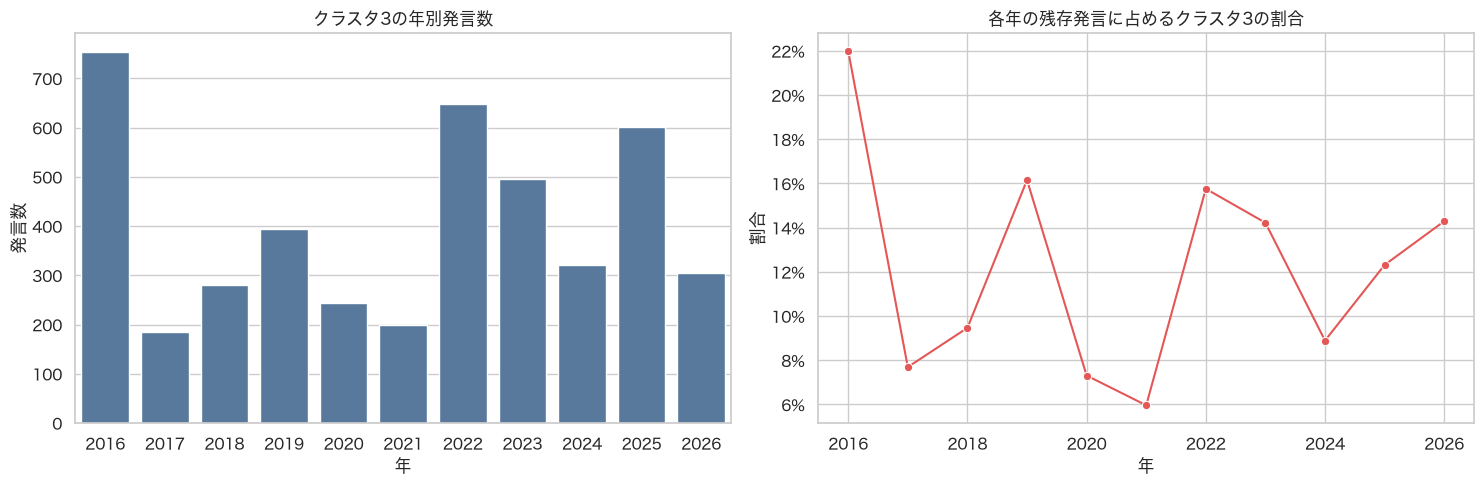

In [3]:
all_year_counts = all_speeches.groupby('year').size().rename('all_retained_speeches')
cluster_year_counts = cluster3.groupby('year').size().rename('cluster3_speeches')
yearly = (
    pd.concat([all_year_counts, cluster_year_counts], axis=1)
    .fillna(0)
    .astype({'all_retained_speeches': 'int64', 'cluster3_speeches': 'int64'})
    .assign(share_within_year=lambda d: d['cluster3_speeches'] / d['all_retained_speeches'])
    .reset_index()
)
assert len(yearly) == 11
display(yearly.style.format({'share_within_year': '{:.1%}'}))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=yearly, x='year', y='cluster3_speeches', color='#4C78A8', ax=axes[0])
axes[0].set(title='クラスタ3の年別発言数', xlabel='年', ylabel='発言数')
sns.lineplot(data=yearly, x='year', y='share_within_year', marker='o', color='#E45756', ax=axes[1])
axes[1].yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
axes[1].set(title='各年の残存発言に占めるクラスタ3の割合', xlabel='年', ylabel='割合')
plt.tight_layout();

## 3. 全期間の月別推移

データの最初の月から取得最終月までを連続した月系列にします。発言がない月は件数0、母数となる残存発言もない月の割合は欠損です。

,month,month_start,all_retained_speeches,cluster3_speeches,share_within_month
0,2016-01,2016-01-01,590,123,20.8%
1,2016-02,2016-02-01,1900,453,23.8%
2,2016-03,2016-03-01,121,29,24.0%
3,2016-04,2016-04-01,0,0,nan%
4,2016-05,2016-05-01,102,22,21.6%
5,2016-06,2016-06-01,0,0,nan%
6,2016-07,2016-07-01,0,0,nan%
7,2016-08,2016-08-01,0,0,nan%
8,2016-09,2016-09-01,192,37,19.3%
9,2016-10,2016-10-01,523,90,17.2%


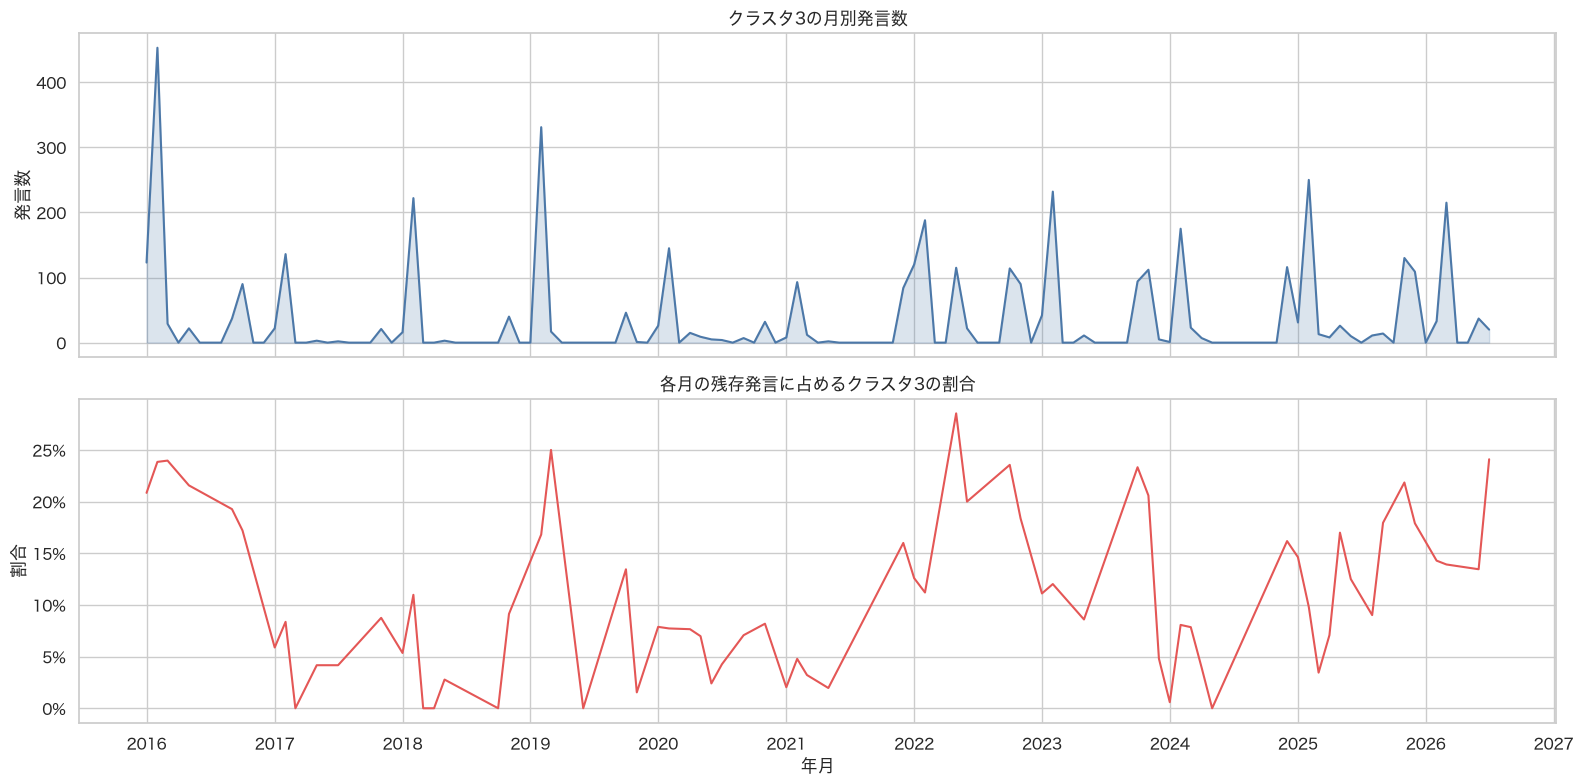

In [4]:
first_month = all_speeches['date'].min().to_period('M')
last_month = all_speeches['date'].max().to_period('M')
full_months = pd.period_range(first_month, last_month, freq='M')
all_month_counts = all_speeches.groupby(all_speeches['date'].dt.to_period('M')).size().reindex(full_months, fill_value=0)
cluster_month_counts = cluster3.groupby(cluster3['date'].dt.to_period('M')).size().reindex(full_months, fill_value=0)
monthly = pd.DataFrame({
    'month': full_months.astype(str),
    'month_start': full_months.to_timestamp(),
    'all_retained_speeches': all_month_counts.to_numpy(dtype='int64'),
    'cluster3_speeches': cluster_month_counts.to_numpy(dtype='int64'),
})
monthly.loc[:, 'share_within_month'] = (
    monthly['cluster3_speeches'] / monthly['all_retained_speeches'].where(monthly['all_retained_speeches'].gt(0))
)
assert monthly['cluster3_speeches'].sum() == len(cluster3)
assert monthly['month'].is_unique
display(monthly.style.format({'share_within_month': '{:.1%}', 'month_start': '{:%Y-%m-%d}'}))
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
sns.lineplot(data=monthly, x='month_start', y='cluster3_speeches', color='#4C78A8', ax=axes[0])
axes[0].fill_between(monthly['month_start'], monthly['cluster3_speeches'], color='#4C78A8', alpha=.2)
axes[0].set(title='クラスタ3の月別発言数', xlabel='', ylabel='発言数')
sns.lineplot(data=monthly, x='month_start', y='share_within_month', color='#E45756', ax=axes[1])
axes[1].yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[1].set(title='各月の残存発言に占めるクラスタ3の割合', xlabel='年月', ylabel='割合')
plt.tight_layout();

## 4. 主要話者・役職・レビュー旗・本文長

,speaker,count
0,岸田文雄,415
1,安倍晋三,379
2,黒田東彦,131
3,高市早苗,125
4,玉木雄一郎,104
5,階猛,99
6,前原誠司,80
7,麻生太郎,70
8,茂木敏充,67
9,加藤勝信,67


,speakerPosition,count
0,役職なし,2346
1,内閣総理大臣,1001
2,内閣府特命担当大臣（経済財政政策）,219
3,財務大臣・内閣府特命担当大臣（金融）,207
4,日本銀行総裁,170
5,厚生労働大臣,95
6,経済産業大臣・内閣府特命担当大臣（原子力損害賠償・廃炉等支援機構）,85
7,内閣府特命担当大臣（経済財政政策・規制改革）,18
8,農林水産大臣,15
9,日本銀行副総裁,13


,review_flags,count
0,なし,4233
1,contains_stage_direction,166
2,very_short_review,29
3,very_short_review;contains_stage_direction,2


,characters
count,4430.000000
mean,562.302032
std,429.079514
min,6.000000
10%,139.000000
25%,272.000000
50%,462.000000
75%,744.000000
90%,1098.000000
max,4088.000000


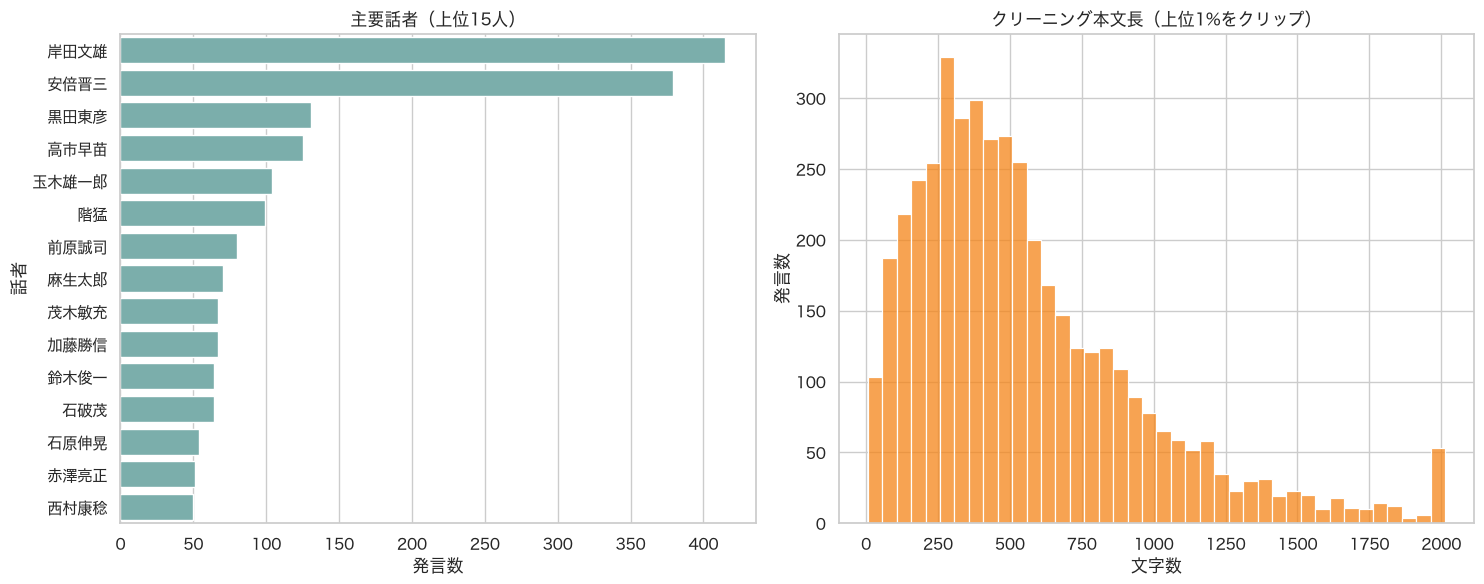

In [5]:
top_speakers = cluster3['speaker'].value_counts().head(20).rename_axis('speaker').reset_index(name='count')
top_positions = cluster3['speakerPosition'].fillna('役職なし').replace('', '役職なし').value_counts().head(20).rename_axis('speakerPosition').reset_index(name='count')
review_flags = cluster3['review_flags'].fillna('なし').replace('', 'なし').value_counts().rename_axis('review_flags').reset_index(name='count')
text_length = cluster3['speech_cleaned'].str.len()
display(top_speakers, top_positions, review_flags)
display(text_length.describe(percentiles=[.1, .25, .5, .75, .9]).rename('characters').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=top_speakers.head(15), y='speaker', x='count', color='#72B7B2', ax=axes[0])
axes[0].set(title='主要話者（上位15人）', xlabel='発言数', ylabel='話者')
sns.histplot(text_length.clip(upper=text_length.quantile(.99)), bins=40, color='#F58518', ax=axes[1])
axes[1].set(title='クリーニング本文長（上位1%をクリップ）', xlabel='文字数', ylabel='発言数')
plt.tight_layout();

## 5. 重心に近い代表発言10件

In [6]:
representatives = cluster3.nsmallest(10, 'centroid_distance').copy()
display(representatives[['speechID', 'date', 'speaker', 'speakerPosition', 'centroid_distance', 'speech_cleaned', 'speechURL']])

,speechID,date,speaker,speakerPosition,centroid_distance,speech_cleaned,speechURL
3591,121905261X00720251210_380,2025-12-10,吉良州司,NaN,0.611123,今の総理の答弁の御認識については、私も全く共有するところであります。 ただ、私自身は、もう少...,https://kokkai.ndl.go.jp/txt/121905261X0072025...
4098,121705261X00220250131_049,2025-01-31,木原誠二,NaN,0.639527,ありがとうございます。 まさに、賃上げを起点に消費の促進につなげ、そしてそれが企業収益の向上...,https://kokkai.ndl.go.jp/txt/121705261X0022025...
2448,120805261X01620220218_270,2022-02-18,玉木雄一郎,NaN,0.643445,国民民主党代表の玉木雄一郎です。 まず、立憲民主党、維新の両党の皆さんに時間をいただいている...,https://kokkai.ndl.go.jp/txt/120805261X0162022...
370,119005261X01220160215_121,2016-02-15,安倍晋三,内閣総理大臣,0.644099,長期ということでしっかりとまず見ていただきたいと思います。この一カ月、一カ月半の値動きだけに...,https://kokkai.ndl.go.jp/txt/119005261X0122016...
3363,121305261X01420240226_312,2024-02-26,吉良州司,NaN,0.644527,有志の会、吉良州司です。 まず、時間配分につき、立憲民主党に感謝申し上げます。 今日は、前回...,https://kokkai.ndl.go.jp/txt/121305261X0142024...
1177,119605261X00420180202_005,2018-02-02,安倍晋三,内閣総理大臣,0.646119,五年間のアベノミクスにより、日本経済は、足元では二十八年ぶりとなる七四半期連続のプラス成長で...,https://kokkai.ndl.go.jp/txt/119605261X0042018...
3365,121305261X01420240226_315,2024-02-26,岸田文雄,内閣総理大臣,0.646481,委員の考え方、興味深く聞かせていただきました。 そして、そもそも、質問の中心はアベノミクスの...,https://kokkai.ndl.go.jp/txt/121305261X0142024...
398,119005261X01220160215_339,2016-02-15,安倍晋三,内閣総理大臣,0.647229,アベノミクス三本の矢の政策によって、もはやデフレではないという状況をつくり出す中で、政権発足...,https://kokkai.ndl.go.jp/txt/119005261X0122016...
3501,121305261X00320240205_016,2024-02-05,加藤勝信,NaN,0.648803,まさに今お話しいただいたように、ヒアリング調査そしてアンケート調査、これをしっかり実施し、も...,https://kokkai.ndl.go.jp/txt/121305261X0032024...
2695,120805261X00220220124_141,2022-01-24,竹内譲,NaN,0.649600,資料の２というのもございまして、お手元に、これも御覧いただきたいわけでございますが、幾つかの...,https://kokkai.ndl.go.jp/txt/120805261X0022022...


## 6. ランダム30発言の内容確認

In [7]:
sample = cluster3.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).copy()
sample.insert(0, 'sample_order', range(1, SAMPLE_SIZE + 1))
sample.loc[:, 'review_decision'] = ''
sample.loc[:, 'review_notes'] = ''
assert len(sample) == SAMPLE_SIZE and sample['speechID'].is_unique
for row in sample.itertuples(index=False):
    position = row.speakerPosition if pd.notna(row.speakerPosition) and str(row.speakerPosition).strip() else '役職なし'
    flags = row.review_flags if pd.notna(row.review_flags) and str(row.review_flags).strip() else 'なし'
    cleaned = str(row.speech_cleaned).replace('\n', '  \n')
    original = str(row.speech).replace('\n', '  \n')
    display(Markdown(
        f"### {row.sample_order}. {row.speaker}（{position}）— {row.date:%Y-%m-%d}\n"
        f"- 発言ID: `{row.speechID}`\n"
        f"- レビューフラグ: {flags}\n"
        f"- 重心距離: {row.centroid_distance:.6f}\n"
        f"- [国会会議録の発言ページ]({row.speechURL})\n\n"
        f"**クリーニング本文**\n\n{cleaned}\n\n"
        f"<details><summary>原文を表示</summary>\n\n{original}\n\n</details>"
    ))

### 1. 権丈英子（亜細亜大学経済学部教授）— 2022-02-04
- 発言ID: `120805261X01020220204_194`
- レビューフラグ: なし
- 重心距離: 0.849629
- [国会会議録の発言ページ](https://kokkai.ndl.go.jp/txt/120805261X01020220204/194)

**クリーニング本文**

ありがとうございます。 優しく強い経済ということでございますね。全く賛成でございます。 効率と公平のトレードオフというふうに経済学でよく言いますけれども、効率と公平はトレードオフではなくて、両者の適切な組合せがやはり必要だというふうに考えております。今日何度か申しましたフレキシビリティーとセキュリティーというのが労働市場でよく使われる言葉ですが、その組合せが大切である。そのバランス、今どこにいて、どちらに向かっていくのか、それをしっかりと判断して考えていくということが必要かと思います。 分配の話も、市場での一次分配、貢献原則に基づく一次分配、そしてこれを補完する形の二次分配、社会保障などになりますけれども、そういった必要原則に基づくもの、しっかりとこれらを組み合わせて優しく強い経済を進めていくということは、とても大切なことだというふうに考えております。 ありがとうございます。

<details><summary>原文を表示</summary>

○権丈参考人　ありがとうございます。  
　優しく強い経済ということでございますね。全く賛成でございます。  
　効率と公平のトレードオフというふうに経済学でよく言いますけれども、効率と公平はトレードオフではなくて、両者の適切な組合せがやはり必要だというふうに考えております。今日何度か申しましたフレキシビリティーとセキュリティーというのが労働市場でよく使われる言葉ですが、その組合せが大切である。そのバランス、今どこにいて、どちらに向かっていくのか、それをしっかりと判断して考えていくということが必要かと思います。  
　分配の話も、市場での一次分配、貢献原則に基づく一次分配、そしてこれを補完する形の二次分配、社会保障などになりますけれども、そういった必要原則に基づくもの、しっかりとこれらを組み合わせて優しく強い経済を進めていくということは、とても大切なことだというふうに考えております。  
　ありがとうございます。

</details>

### 2. 石原伸晃（内閣府特命担当大臣（経済財政政策））— 2017-02-08
- 発言ID: `119305261X00920170208_189`
- レビューフラグ: なし
- 重心距離: 0.736853
- [国会会議録の発言ページ](https://kokkai.ndl.go.jp/txt/119305261X00920170208/189)

**クリーニング本文**

政府といたしましては、中長期的に実質二％、名目三％程度を上回る民需主導の持続的な経済成長を実現する、その結果として、ただいま委員が御指摘になりました、二〇二〇年ごろに名目ＧＤＰ六百兆円を達成することを目指しているということでございます。 そして、どの程度数字が積み重なっているのかという御質問だったと思うんですけれども、政権交代いたしまして、四年間で名目ＧＤＰは四十四兆円、年平均ですと二・三％程度、実質ですと二十五兆円、年平均ですと一・三％ということで、総理も再三御答弁させていただいておりますように、デフレではないという状態に至っているんだと思います。こうした中、これも当予算委員会で総理から申し述べておりますけれども、三本の矢の政策に取り組むことによりまして六百兆円の経済を目指していく。 そして、委員は、どういうところに行く、どう積み上がっているのかということが前段の御質問でございましたけれども、日本全体のマクロ経済として達成すべき目標でございまして、あらかじめ計画経済のように産業や地域ごとに積み上げてこれを達成するというものではなくて、あくまで民需主導の経済成長の中でこの数字を達成する、マクロの数字であるというふうに御理解いただければと存じます。

<details><summary>原文を表示</summary>

○石原国務大臣　政府といたしましては、中長期的に実質二％、名目三％程度を上回る民需主導の持続的な経済成長を実現する、その結果として、ただいま委員が御指摘になりました、二〇二〇年ごろに名目ＧＤＰ六百兆円を達成することを目指しているということでございます。  
　そして、どの程度数字が積み重なっているのかという御質問だったと思うんですけれども、政権交代いたしまして、四年間で名目ＧＤＰは四十四兆円、年平均ですと二・三％程度、実質ですと二十五兆円、年平均ですと一・三％ということで、総理も再三御答弁させていただいておりますように、デフレではないという状態に至っているんだと思います。こうした中、これも当予算委員会で総理から申し述べておりますけれども、三本の矢の政策に取り組むことによりまして六百兆円の経済を目指していく。  
　そして、委員は、どういうところに行く、どう積み上がっているのかということが前段の御質問でございましたけれども、日本全体のマクロ経済として達成すべき目標でございまして、あらかじめ計画経済のように産業や地域ごとに積み上げてこれを達成するというものではなくて、あくまで民需主導の経済成長の中でこの数字を達成する、マクロの数字であるというふうに御理解いただければと存じます。

</details>

### 3. 赤澤亮正（内閣府特命担当大臣（経済財政政策））— 2025-02-03
- 発言ID: `121705261X00320250203_227`
- レビューフラグ: なし
- 重心距離: 0.743551
- [国会会議録の発言ページ](https://kokkai.ndl.go.jp/txt/121705261X00320250203/227)

**クリーニング本文**

物価については、いろいろ御議論がある中ですけれども、まず、国民の皆様が物価上昇で生活が、あるいは経営者の皆さんであれば経営が大分厳しいという認識を持っておられることについては我々も強い問題意識を持っております。 その中で、これは岡本委員は御案内でおっしゃっていると思いますが、日銀がまず物価安定目標を二％と言っているものは、これは基調的な物価上昇と言われるもので、経済が順調に進んでいるとき、生産性が向上して賃上げも伴う形で望ましい形の物価上昇が起きる、その物価上昇を基本的に二・〇％に持っていきたいというのがアコードに書いてあることです。 その上で、国民の皆様が直面している物価というのはちょっとそれと別のもので、いわゆる輸入物価が上がることで上がってしまうようなコストプッシュの部分も乗ったもので、消費者物価の総合と言われるものです。 その二つがちょっと入り交じっているので分かりづらいところでありますが、資本主義社会において経済が順調に成長していくためには、基調的な物価上昇、これは物価安定目標に書いてある二・〇。そして、国民の皆様がコストプッシュ型の物価上昇で苦しんでおられるときにはきちっと対策を講じるということで経済を成長させていこうというのが基本的な考え方であります。 アコードについて言えば、そういう意味で、岡本委員も御案内のとおりと思いますが、書いてあることはまさに基調的な物価上昇を二％に持っていくということで、今ようやくそれが少しずつ上がって二％に近づいているという認識であります。一方で、国民の皆様が直面している物価上昇というのは、それにコストプッシュが乗っかった、コストプッシュも乗っけた消費者物価総合というものなので、そこについては丁寧に説明をして、書いてあることについてはまさに今も意味は変わっているわけではありませんし、それをきちっと実現していくことが重要であると我々は共通認識として持っているということを御理解いただけるようにしていきたいと思います。

<details><summary>原文を表示</summary>

○赤澤国務大臣　物価については、いろいろ御議論がある中ですけれども、まず、国民の皆様が物価上昇で生活が、あるいは経営者の皆さんであれば経営が大分厳しいという認識を持っておられることについては我々も強い問題意識を持っております。  
　その中で、これは岡本委員は御案内でおっしゃっていると思いますが、日銀がまず物価安定目標を二％と言っているものは、これは基調的な物価上昇と言われるもので、経済が順調に進んでいるとき、生産性が向上して賃上げも伴う形で望ましい形の物価上昇が起きる、その物価上昇を基本的に二・〇％に持っていきたいというのがアコードに書いてあることです。  
　その上で、国民の皆様が直面している物価というのはちょっとそれと別のもので、いわゆる輸入物価が上がることで上がってしまうようなコストプッシュの部分も乗ったもので、消費者物価の総合と言われるものです。  
　その二つがちょっと入り交じっているので分かりづらいところでありますが、資本主義社会において経済が順調に成長していくためには、基調的な物価上昇、これは物価安定目標に書いてある二・〇。そして、国民の皆様がコストプッシュ型の物価上昇で苦しんでおられるときにはきちっと対策を講じるということで経済を成長させていこうというのが基本的な考え方であります。  
　アコードについて言えば、そういう意味で、岡本委員も御案内のとおりと思いますが、書いてあることはまさに基調的な物価上昇を二％に持っていくということで、今ようやくそれが少しずつ上がって二％に近づいているという認識であります。一方で、国民の皆様が直面している物価上昇というのは、それにコストプッシュが乗っかった、コストプッシュも乗っけた消費者物価総合というものなので、そこについては丁寧に説明をして、書いてあることについてはまさに今も意味は変わっているわけではありませんし、それをきちっと実現していくことが重要であると我々は共通認識として持っているということを御理解いただけるようにしていきたいと思います。

</details>

### 4. 安倍晋三（内閣総理大臣）— 2018-11-02
- 発言ID: `119705261X00320181102_366`
- レビューフラグ: なし
- 重心距離: 0.781006
- [国会会議録の発言ページ](https://kokkai.ndl.go.jp/txt/119705261X00320181102/366)

**クリーニング本文**

これは、税収が伸びていないということではなくて、今年度の税収も六十兆円に近づく、六十兆円を超えて、いわば過去最高に近づきつつあるわけでございますし、地方税収も過去最高、四十兆円を超えているわけでございまして、今後も、しっかりと経済を成長させ、税収も安定的にふえていくように、アベノミクスを更に加速し、充実をしていきたい、このように考えております。

<details><summary>原文を表示</summary>

○安倍内閣総理大臣　これは、税収が伸びていないということではなくて、今年度の税収も六十兆円に近づく、六十兆円を超えて、いわば過去最高に近づきつつあるわけでございますし、地方税収も過去最高、四十兆円を超えているわけでございまして、今後も、しっかりと経済を成長させ、税収も安定的にふえていくように、アベノミクスを更に加速し、充実をしていきたい、このように考えております。

</details>

### 5. 谷畑孝（役職なし）— 2016-02-19
- 発言ID: `119005261X01520160219_262`
- レビューフラグ: なし
- 重心距離: 0.875003
- [国会会議録の発言ページ](https://kokkai.ndl.go.jp/txt/119005261X01520160219/262)

**クリーニング本文**

厚生労働省としては、そういう正規と非正規の垣根を取っていくための施策をされておると。そこへ、プラス一億総活躍という形の中で、同一労働同一賃金ということで、これは総理が肝いりでさらにそれを前へ向けていくんだ、こういうふうに本会議場で、総理が施政演説でおっしゃったわけです。 私は、一億総活躍社会の実現のためには、やはり多様な働き方が認められて、そして一人一人が夢と希望を持って働いていける、こういう社会というのは本当にすばらしい社会だ、そう思うんですね。その意味においては、やはり同一労働同一賃金というものの実現は私は非常に大事だ、こう思っています。 これを実現していくのには、いろいろな障害、壁というのがあると思うんです。 例えば、我々、よくヨーロッパへ視察に行く場合、ヨーロッパにおいては日本みたいな企業別労働組合じゃないですし、産別でありますし、それから、職務給制度という形の中で、いわゆる同一労働同一賃金の定義というのがすっきりするし、そして実施もしやすい。だから、私がオランダへ行ったときなどは、正規と非正規の垣根がない、あるのは長時間働くか短時間働くか、こういうことを聞いて、私どももびっくりし、何とすごいんだろう、こう思ったものです。 それでまた、これを実現していこうとすれば、企業側から見ても、ひょっとしたら賃金が上がって負担が大きくなって企業が潰れるんじゃないか、こういう不安もあるだろうし、また、正社員から見たら、非正規がどんどん待遇がよくなってきたら我々自身の賃金が下がるんじゃないのか。こういうさまざまな障害がある。 そのことの中で同一労働同一賃金というのを実現していくということですから、これは大変なことだと思うので、総理、そこらの点は踏まえながら、どういう形を踏んで担保していくのか、一言お願いします。

<details><summary>原文を表示</summary>

○谷畑委員　厚生労働省としては、そういう正規と非正規の垣根を取っていくための施策をされておると。そこへ、プラス一億総活躍という形の中で、同一労働同一賃金ということで、これは総理が肝いりでさらにそれを前へ向けていくんだ、こういうふうに本会議場で、総理が施政演説でおっしゃったわけです。  
　私は、一億総活躍社会の実現のためには、やはり多様な働き方が認められて、そして一人一人が夢と希望を持って働いていける、こういう社会というのは本当にすばらしい社会だ、そう思うんですね。その意味においては、やはり同一労働同一賃金というものの実現は私は非常に大事だ、こう思っています。  
　これを実現していくのには、いろいろな障害、壁というのがあると思うんです。  
　例えば、我々、よくヨーロッパへ視察に行く場合、ヨーロッパにおいては日本みたいな企業別労働組合じゃないですし、産別でありますし、それから、職務給制度という形の中で、いわゆる同一労働同一賃金の定義というのがすっきりするし、そして実施もしやすい。だから、私がオランダへ行ったときなどは、正規と非正規の垣根がない、あるのは長時間働くか短時間働くか、こういうことを聞いて、私どももびっくりし、何とすごいんだろう、こう思ったものです。  
　それでまた、これを実現していこうとすれば、企業側から見ても、ひょっとしたら賃金が上がって負担が大きくなって企業が潰れるんじゃないか、こういう不安もあるだろうし、また、正社員から見たら、非正規がどんどん待遇がよくなってきたら我々自身の賃金が下がるんじゃないのか。こういうさまざまな障害がある。  
　そのことの中で同一労働同一賃金というのを実現していくということですから、これは大変なことだと思うので、総理、そこらの点は踏まえながら、どういう形を踏んで担保していくのか、一言お願いします。

</details>

...

### 26. 藤岡隆雄（役職なし）— 2023-02-06
- 発言ID: `121105261X00720230206_264`
- レビューフラグ: なし
- 重心距離: 0.978238
- [国会会議録の発言ページ](https://kokkai.ndl.go.jp/txt/121105261X00720230206/264)

**クリーニング本文**

本当に隠れ防衛費的になってしまうということの懸念を私は伝えておきたいということを思います。 では、続いて、日銀総裁、黒田総裁、済みません、お待たせいたしました。大変お疲れのことだと思いますけれども、ありがとうございます。一点お伺いをさせていただきたいと思います。 資料をお配りしております。日銀総裁の記者会見で、十二月に金融政策決定会合で、いわゆるイールドカーブコントロール、これを柔軟化といいますか、プラスマイナス〇・五％まで許容変動幅をしたという中で、総裁は、九月二十六日の大阪での会見では、〇・二五％程度となっています、この許容上限を日銀が引き上げることは総裁がおっしゃる金利引上げあるいは金融引締めになるのか、改めて教えてくださいというふうに問われて、そうなると思いますというふうにお答えしているわけなんですよね。その後、また、今回の新たな変更後の十二月二十日の記者会見におきまして、事実上の利上げには当たらないんでしょうかというふうに問われて、資料に線を引いていなかったです、済みません、答えの六行目に、利上げではありませんというふうに答えているんですね。 これはある意味違うことを話しているんですけれども、総裁、これはどういうことでございましょうか。

<details><summary>原文を表示</summary>

○藤岡委員　本当に隠れ防衛費的になってしまうということの懸念を私は伝えておきたいということを思います。  
　では、続いて、日銀総裁、黒田総裁、済みません、お待たせいたしました。大変お疲れのことだと思いますけれども、ありがとうございます。一点お伺いをさせていただきたいと思います。  
　資料をお配りしております。日銀総裁の記者会見で、十二月に金融政策決定会合で、いわゆるイールドカーブコントロール、これを柔軟化といいますか、プラスマイナス〇・五％まで許容変動幅をしたという中で、総裁は、九月二十六日の大阪での会見では、〇・二五％程度となっています、この許容上限を日銀が引き上げることは総裁がおっしゃる金利引上げあるいは金融引締めになるのか、改めて教えてくださいというふうに問われて、そうなると思いますというふうにお答えしているわけなんですよね。その後、また、今回の新たな変更後の十二月二十日の記者会見におきまして、事実上の利上げには当たらないんでしょうかというふうに問われて、資料に線を引いていなかったです、済みません、答えの六行目に、利上げではありませんというふうに答えているんですね。  
　これはある意味違うことを話しているんですけれども、総裁、これはどういうことでございましょうか。

</details>

### 27. 菅原一秀（役職なし）— 2016-02-10
- 発言ID: `119005261X01120160210_056`
- レビューフラグ: なし
- 重心距離: 0.878579
- [国会会議録の発言ページ](https://kokkai.ndl.go.jp/txt/119005261X01120160210/56)

**クリーニング本文**

先に手を挙げています。経済再生担当大臣石原伸晃君。 その後、総理。

<details><summary>原文を表示</summary>

○菅原委員長代理　先に手を挙げています。経済再生担当大臣石原伸晃君。  
　その後、総理。

</details>

### 28. 清水誠一（日本銀行理事）— 2024-02-08
- 発言ID: `121305261X00620240208_024`
- レビューフラグ: なし
- 重心距離: 0.790589
- [国会会議録の発言ページ](https://kokkai.ndl.go.jp/txt/121305261X00620240208/24)

**クリーニング本文**

お答え申し上げます。 日本銀行は、賃金の上昇を伴う形で二％の物価安定の目標を持続的、安定的に実現することを目指しております。 これまでの物価上昇は既往の輸入物価上昇というコストプッシュによるところが大きいと見ておりますが、日本銀行としましては、物価安定の目標が持続的、安定的に実現していくためには、賃金と物価の好循環が強まり、基調的な物価上昇率が高まっていくことが重要と考えてございます。この先、丹念にいろいろデータ等を確認してまいりますけれども、賃金と物価の好循環を確認し、物価安定の目標の持続的、安定的な実現が見通せる状況に至りますと、マイナス金利を含む大規模な緩和策の継続の是非を検討していくことになります。 もとより、政策修正の具体的な内容は、その時点の経済、物価、金融情勢次第ではございますが、現時点での経済、物価見通しを前提といたしますと、先行き、マイナス金利の解除等を実現したとしても、緩和的な金融環境は当面続くというふうに考えてございます。

<details><summary>原文を表示</summary>

○清水参考人　お答え申し上げます。  
　日本銀行は、賃金の上昇を伴う形で二％の物価安定の目標を持続的、安定的に実現することを目指しております。  
　これまでの物価上昇は既往の輸入物価上昇というコストプッシュによるところが大きいと見ておりますが、日本銀行としましては、物価安定の目標が持続的、安定的に実現していくためには、賃金と物価の好循環が強まり、基調的な物価上昇率が高まっていくことが重要と考えてございます。この先、丹念にいろいろデータ等を確認してまいりますけれども、賃金と物価の好循環を確認し、物価安定の目標の持続的、安定的な実現が見通せる状況に至りますと、マイナス金利を含む大規模な緩和策の継続の是非を検討していくことになります。  
　もとより、政策修正の具体的な内容は、その時点の経済、物価、金融情勢次第ではございますが、現時点での経済、物価見通しを前提といたしますと、先行き、マイナス金利の解除等を実現したとしても、緩和的な金融環境は当面続くというふうに考えてございます。

</details>

### 29. 緒方林太郎（役職なし）— 2016-02-15
- 発言ID: `119005261X01220160215_122`
- レビューフラグ: なし
- 重心距離: 0.853576
- [国会会議録の発言ページ](https://kokkai.ndl.go.jp/txt/119005261X01220160215/122)

**クリーニング本文**

先ほどから外的な要因を非常に強調されますが、しかしながら、まさに、そういう外的な要因に対応する力強い足腰のある日本経済をつくるというのがアベノミクスの三本目の矢じゃなかったのかなというふうに思うわけですね。三本目の矢を適切に打っていくことによって、こういった外的要因に影響されないような経済をつくっていくということ、私はこれがアベノミクスの三本目の矢だったというふうに思っております。 安倍総理にお伺いいたします。 これまで打ってきた三本目の矢によって、この状況というのはもっとよりよい状況にできたんじゃないかというふうに思うわけですが、安倍総理、いかがですか。

<details><summary>原文を表示</summary>

○緒方委員　先ほどから外的な要因を非常に強調されますが、しかしながら、まさに、そういう外的な要因に対応する力強い足腰のある日本経済をつくるというのがアベノミクスの三本目の矢じゃなかったのかなというふうに思うわけですね。三本目の矢を適切に打っていくことによって、こういった外的要因に影響されないような経済をつくっていくということ、私はこれがアベノミクスの三本目の矢だったというふうに思っております。  
　安倍総理にお伺いいたします。  
　これまで打ってきた三本目の矢によって、この状況というのはもっとよりよい状況にできたんじゃないかというふうに思うわけですが、安倍総理、いかがですか。

</details>

### 30. 麻生太郎（財務大臣・内閣府特命担当大臣（金融））— 2016-02-29
- 発言ID: `119005261X01720160229_005`
- レビューフラグ: なし
- 重心距離: 0.745548
- [国会会議録の発言ページ](https://kokkai.ndl.go.jp/txt/119005261X01720160229/5)

**クリーニング本文**

今回、上海のＧ20におきましては、いわゆる世界経済について金融市場の動向とか変動とか不確実性がいろいろ高まっている中で、最近の市場の変動の規模とか大きさとか、そういったようなものはその根底にあります世界経済のファンダメンタルズというものを反映したものではないという認識で一致をいたしております。 その上で、世界経済のより強固で持続可能性がありかつ均衡性のとれた成長を実現するためには、金融とか財政とか構造改革等々全ての政策手段というものを個別または総合的に用いるということでコミュニケの上でも合意をいたしておりますので、市場に対しては安心感を与えるものができ上がったと思っております。

<details><summary>原文を表示</summary>

○麻生国務大臣　今回、上海のＧ20におきましては、いわゆる世界経済について金融市場の動向とか変動とか不確実性がいろいろ高まっている中で、最近の市場の変動の規模とか大きさとか、そういったようなものはその根底にあります世界経済のファンダメンタルズというものを反映したものではないという認識で一致をいたしております。  
　その上で、世界経済のより強固で持続可能性がありかつ均衡性のとれた成長を実現するためには、金融とか財政とか構造改革等々全ての政策手段というものを個別または総合的に用いるということでコミュニケの上でも合意をいたしておりますので、市場に対しては安心感を与えるものができ上がったと思っております。

</details>

## 7. 分析表とレビュー標本の出力

In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cluster3.to_csv(OUTPUT_DIR / 'cluster_3_speeches.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
yearly.to_csv(OUTPUT_DIR / 'cluster_3_yearly.csv', index=False, encoding='utf-8-sig')
monthly.to_csv(OUTPUT_DIR / 'cluster_3_monthly.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
top_speakers.to_csv(OUTPUT_DIR / 'cluster_3_top_speakers.csv', index=False, encoding='utf-8-sig')
representatives.to_csv(OUTPUT_DIR / 'cluster_3_representative_10.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
sample.to_csv(OUTPUT_DIR / 'cluster_3_random_30.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
assert len(pd.read_csv(OUTPUT_DIR / 'cluster_3_speeches.csv', encoding='utf-8-sig')) == len(cluster3)
assert pd.read_csv(OUTPUT_DIR / 'cluster_3_monthly.csv', encoding='utf-8-sig')['cluster3_speeches'].sum() == len(cluster3)
assert len(pd.read_csv(OUTPUT_DIR / 'cluster_3_random_30.csv', encoding='utf-8-sig')) == SAMPLE_SIZE
print(f'出力先: {OUTPUT_DIR}')
print(f'検証完了: クラスタ3 {len(cluster3):,}件、代表発言{len(representatives)}件、ランダム標本{len(sample)}件')

出力先: /Users/tasskkiu2/kokkai/analysis/cluster_3_economy
検証完了: クラスタ3 4,430件、代表発言10件、ランダム標本30件
